# Task 5 - Netflix Trend Forecasting Model
## **Time Series Forecasting & Predictive Analytics**


### **Task Workflow:**
1. **Step 1: Prepare time-based features** - Parse timestamps, extract calendar components (year, month, quarter, day-of-week), and construct continuous monthly release time series.
2. **Step 2: Analyze historical release patterns** - Explore addition trajectories, analyze day-of-week drops (e.g. Friday releases), and perform seasonal decomposition (Trend, Seasonality, Residuals).
3. **Step 3: Build forecasting models** - Engineer lag variables ($t-1, t-2, t-12$) and rolling averages; train **Holt-Winters Exponential Smoothing**, **Random Forest Time Series Regressor**, and **Gradient Boosting Regressor**.
4. **Step 4: Generate future predictions** - Forecast future release volumes across a 12-to-24 month forward-looking horizon.
5. **Step 5: Evaluate forecasting accuracy** - Assess prediction errors using MAE, RMSE, and MAPE, and extract actionable platform insights.

---

## **Environment Setup & Imports**

In [1]:
# Core scientific and visualization libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

# Time series decomposition & statistical forecasting
from statsmodels.tsa.seasonal import seasonal_decompose
from statsmodels.tsa.holtwinters import ExponentialSmoothing

# Machine Learning Regressors
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.linear_model import Ridge

# Evaluation Metrics
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Google Colab check
try:
    from google.colab import files
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

print(f"Setup complete. Running in Google Colab: {IN_COLAB}")

Setup complete. Running in Google Colab: True


## **Step 1: Prepare Time-Based Features**

In this step, we:
1. Load `Dataset.csv` and parse `date_added` into standard `datetime64` format.
2. Drop rows missing valid dates.
3. Extract key temporal components:
   - `year_added`, `month_added`, `quarter_added`, `day_name`, `is_weekend`.
4. Aggregate title additions into a continuous monthly sequence (`YYYY-MM`) with zero-filling for continuous continuity.
5. Create separate tracking series for Total Additions, Movie Additions, and TV Show Additions.

In [2]:
# Load dataset
dataset_path = '/content/Dataset.csv'

try:
    df = pd.read_csv(dataset_path)
except FileNotFoundError:
    print("Dataset.csv not found in working directory. Please upload Dataset.csv.")
    if IN_COLAB:
        uploaded = files.upload()
        dataset_path = list(uploaded.keys())[0]
        df = pd.read_csv(dataset_path)

# Parse date_added to datetime
df['date_added_dt'] = pd.to_datetime(df['date_added'].astype(str).str.strip(), errors='coerce')
df_time = df.dropna(subset=['date_added_dt']).copy()
df_time = df_time.sort_values(by='date_added_dt').reset_index(drop=True)

# Extract time-based features
df_time['year_added'] = df_time['date_added_dt'].dt.year.astype(int)
df_time['month_added'] = df_time['date_added_dt'].dt.month.astype(int)
df_time['quarter_added'] = df_time['date_added_dt'].dt.quarter.astype(int)
df_time['day_name'] = df_time['date_added_dt'].dt.day_name()
df_time['period_month'] = df_time['date_added_dt'].dt.to_period('M')

print(f"Valid date records: {len(df_time)} of {len(df)} titles")
print(f"Date Range: {df_time['date_added_dt'].min().strftime('%Y-%m-%d')} to {df_time['date_added_dt'].max().strftime('%Y-%m-%d')}\n")
display(df_time[['title', 'type', 'date_added_dt', 'year_added', 'month_added', 'day_name']].head(3))

Valid date records: 8790 of 8790 titles
Date Range: 2008-01-01 to 2021-09-25



,title,type,date_added_dt,year_added,month_added,day_name
0,To and From New York,Movie,2008-01-01,2008,1,Tuesday
1,Dinner for Five,TV Show,2008-02-04,2008,2,Monday
2,Just Another Love Story,Movie,2009-05-05,2009,5,Tuesday


In [3]:
# Construct regular monthly aggregated time series
# Filter from 2015 onwards where platform additions became consistent and systematic
df_filtered_time = df_time[df_time['year_added'] >= 2015].copy()

# Monthly counts for Total, Movies, and TV Shows
monthly_total = df_filtered_time.groupby('period_month').size().rename('total_additions')
monthly_movies = df_filtered_time[df_filtered_time['type'] == 'Movie'].groupby('period_month').size().rename('movie_additions')
monthly_tv = df_filtered_time[df_filtered_time['type'] == 'TV Show'].groupby('period_month').size().rename('tv_additions')

# Combine and reindex to complete date range with frequency 'M'
full_idx = pd.period_range(start=monthly_total.index.min(), end=monthly_total.index.max(), freq='M')
ts_df = pd.DataFrame(index=full_idx)
ts_df['total_additions'] = monthly_total.reindex(full_idx, fill_value=0)
ts_df['movie_additions'] = monthly_movies.reindex(full_idx, fill_value=0)
ts_df['tv_additions'] = monthly_tv.reindex(full_idx, fill_value=0)

# Convert period index to timestamp index for statsmodels
ts_df.index = ts_df.index.to_timestamp(freq='M')

print(f"Monthly Time Series Points: {len(ts_df)} months")
display(ts_df.head())

Monthly Time Series Points: 81 months


,total_additions,movie_additions,tv_additions
2015-01-31,1,1,0
2015-02-28,4,3,1
2015-03-31,5,3,2
2015-04-30,5,1,4
2015-05-31,6,5,1


## **Step 2: Analyze Historical Release Patterns**

In this step, we analyze the historical trends and empirical properties of Netflix releases:
1. **Long-Term Trajectory:** Overall monthly addition volume over the years.
2. **Format Comparison:** Movies vs. TV Shows monthly cadence.
3. **Day-of-Week Distribution:** Demonstrates Netflix's standard strategic release day (Friday drops).
4. **Seasonal Decomposition:** Decomposes total monthly additions into **Trend**, **Seasonal (12-month cycle)**, and **Residual (noise)** components using additive decomposition:
   $$Y_t = \text{Trend}_t + \text{Seasonal}_t + \text{Residual}_t$$

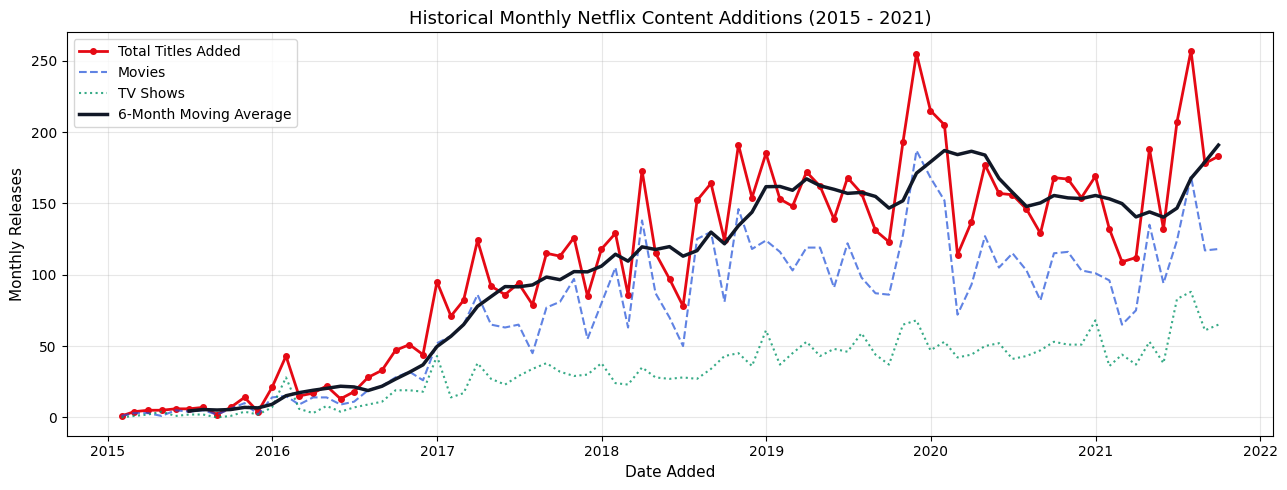

In [4]:
# Plot 1: Historical Monthly Addition Trajectory
plt.figure(figsize=(13, 5))
plt.plot(ts_df.index, ts_df['total_additions'], marker='o', markersize=4, color='#e50914', label='Total Titles Added', linewidth=2)
plt.plot(ts_df.index, ts_df['movie_additions'], linestyle='--', color='#1d4ed8', label='Movies', alpha=0.7)
plt.plot(ts_df.index, ts_df['tv_additions'], linestyle=':', color='#059669', label='TV Shows', alpha=0.8)

# 6-Month Rolling Average
plt.plot(ts_df.index, ts_df['total_additions'].rolling(6).mean(), color='#111827', linewidth=2.5, label='6-Month Moving Average')

plt.title('Historical Monthly Netflix Content Additions (2015 - 2021)', fontsize=13)
plt.xlabel('Date Added', fontsize=11)
plt.ylabel('Monthly Releases', fontsize=11)
plt.legend(frameon=True)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

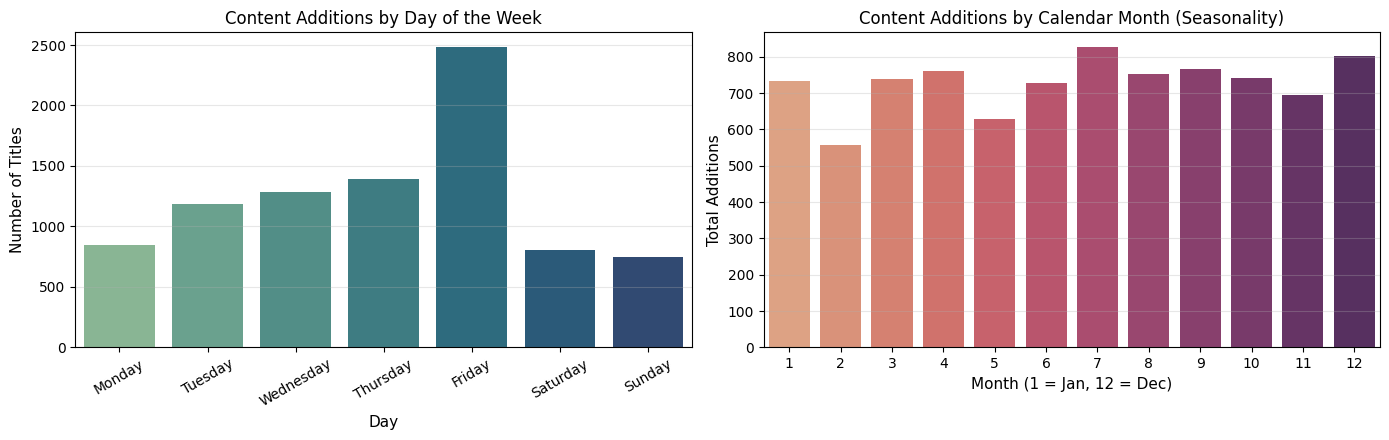

In [5]:
# Plot 2: Day of Week & Monthly Seasonality
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 4.5))

# Day of week additions
day_order = ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday']
sns.countplot(data=df_filtered_time, x='day_name', order=day_order, palette='crest', ax=ax1)
ax1.set_title('Content Additions by Day of the Week', fontsize=12)
ax1.set_xlabel('Day', fontsize=11)
ax1.set_ylabel('Number of Titles', fontsize=11)
ax1.tick_params(axis='x', rotation=30)
ax1.grid(axis='y', alpha=0.3)

# Monthly seasonality (Average additions per calendar month)
monthly_seasonality = df_filtered_time.groupby('month_added').size()
sns.barplot(x=monthly_seasonality.index, y=monthly_seasonality.values, palette='flare', ax=ax2)
ax2.set_title('Content Additions by Calendar Month (Seasonality)', fontsize=12)
ax2.set_xlabel('Month (1 = Jan, 12 = Dec)', fontsize=11)
ax2.set_ylabel('Total Additions', fontsize=11)
ax2.grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.show()

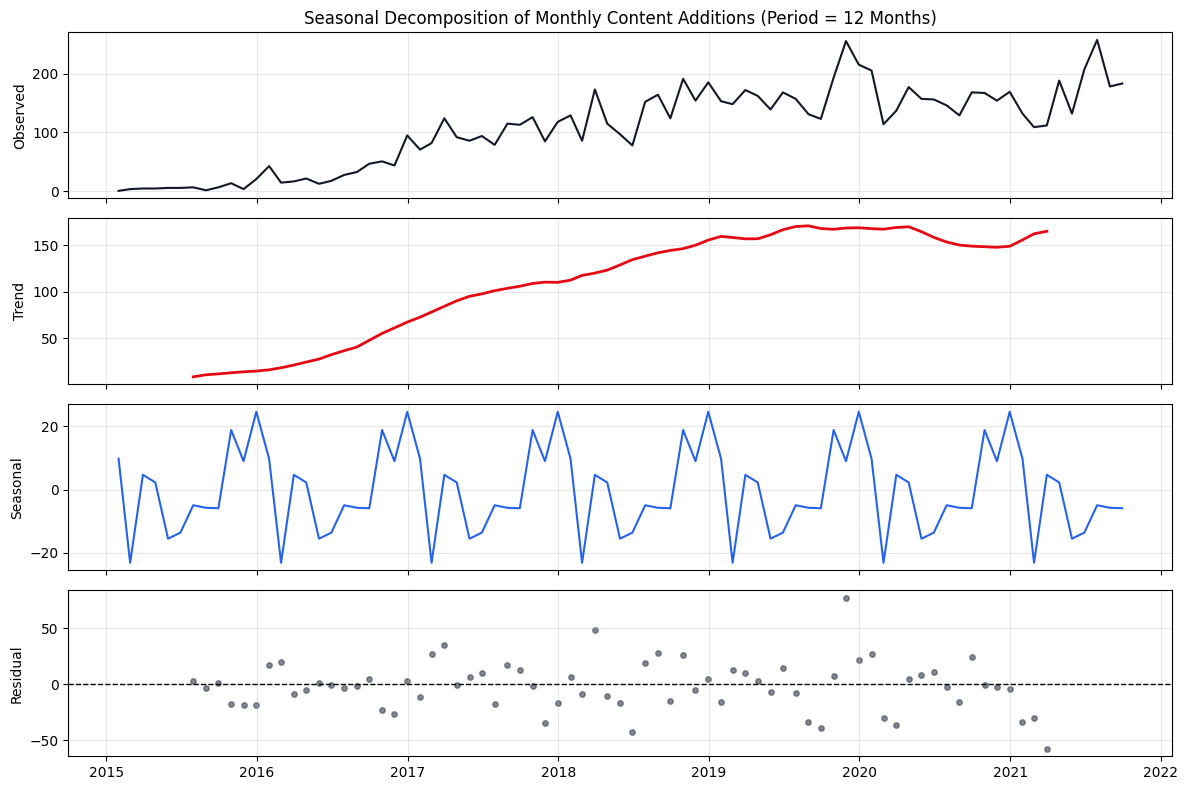

In [6]:
# Plot 3: Time Series Seasonal Decomposition
decomposition = seasonal_decompose(ts_df['total_additions'], model='additive', period=12)

fig, (ax1, ax2, ax3, ax4) = plt.subplots(4, 1, figsize=(12, 8), sharex=True)
ax1.plot(decomposition.observed, color='#111827', linewidth=1.5)
ax1.set_ylabel('Observed', fontsize=10)
ax1.set_title('Seasonal Decomposition of Monthly Content Additions (Period = 12 Months)', fontsize=12)
ax1.grid(alpha=0.3)

ax2.plot(decomposition.trend, color='#e50914', linewidth=2)
ax2.set_ylabel('Trend', fontsize=10)
ax2.grid(alpha=0.3)

ax3.plot(decomposition.seasonal, color='#2563eb', linewidth=1.5)
ax3.set_ylabel('Seasonal', fontsize=10)
ax3.grid(alpha=0.3)

ax4.scatter(decomposition.resid.index, decomposition.resid, color='#4b5563', s=15, alpha=0.7)
ax4.axhline(0, color='black', linestyle='--', linewidth=1)
ax4.set_ylabel('Residual', fontsize=10)
ax4.grid(alpha=0.3)

plt.tight_layout()
plt.show()

## **Step 3: Build Forecasting Models**

We implement both classical statistical and supervised machine learning forecasting approaches:

1. **Holt-Winters Exponential Smoothing:**
   - Captures baseline level, additive trend, and 12-month seasonal cycles.
2. **Supervised ML Forecasting (Feature Engineering):**
   - Transform the time series into supervised learning format using autoregressive lag variables:
     - **Lags:** $y_{t-1}, y_{t-2}, y_{t-3}, y_{t-6}, y_{t-12}$ (1-year seasonal lag).
     - **Rolling Statistics:** 3-month rolling mean ($MA_3$), 6-month rolling mean ($MA_6$).
     - **Calendar Features:** Month integer and cyclical sine/cosine transforms.
   - Train **Random Forest Regressor** and **Gradient Boosting Regressor**.
3. **Chronological Train/Test Split:**
   - Split data preserving time order (last 12 months reserved as holdout test period).

In [7]:
# Supervised Feature Engineering on Time Series
def create_time_series_features(series, lag_list=[1, 2, 3, 6, 12]):
    df_feat = pd.DataFrame({'y': series})

    # Autoregressive Lag Features
    for lag in lag_list:
        df_feat[f'lag_{lag}'] = df_feat['y'].shift(lag)

    # Rolling Window Averages
    df_feat['rolling_mean_3'] = df_feat['y'].shift(1).rolling(3).mean()
    df_feat['rolling_mean_6'] = df_feat['y'].shift(1).rolling(6).mean()
    df_feat['rolling_std_6'] = df_feat['y'].shift(1).rolling(6).std()

    # Calendar & Cyclical features
    months = df_feat.index.month
    df_feat['month'] = months
    df_feat['sin_month'] = np.sin(2 * np.pi * months / 12)
    df_feat['cos_month'] = np.cos(2 * np.pi * months / 12)

    # Drop rows containing NaN due to 12-month lag
    return df_feat.dropna()

features_df = create_time_series_features(ts_df['total_additions'])

# Chronological Train/Test Split (Reserve final 10 months as Test Horizon)
TEST_MONTHS = 10
train_data = features_df.iloc[:-TEST_MONTHS]
test_data = features_df.iloc[-TEST_MONTHS:]

X_train = train_data.drop(columns=['y'])
y_train = train_data['y']
X_test = test_data.drop(columns=['y'])
y_test = test_data['y']

print(f"Training Horizon: {train_data.index.min().strftime('%Y-%m')} to {train_data.index.max().strftime('%Y-%m')} ({len(train_data)} months)")
print(f"Testing Horizon : {test_data.index.min().strftime('%Y-%m')} to {test_data.index.max().strftime('%Y-%m')} ({len(test_data)} months)")

Training Horizon: 2016-01 to 2020-11 (59 months)
Testing Horizon : 2020-12 to 2021-09 (10 months)


In [8]:
# Model 1: Holt-Winters Exponential Smoothing
hw_model = ExponentialSmoothing(
    ts_df['total_additions'].iloc[:-TEST_MONTHS],
    trend='add',
    seasonal='add',
    seasonal_periods=12
).fit(smoothing_level=0.3, smoothing_trend=0.1, smoothing_seasonal=0.2)

hw_preds = hw_model.forecast(steps=TEST_MONTHS)

# Model 2: Random Forest Time Series Regressor
rf_reg = RandomForestRegressor(n_estimators=100, max_depth=6, random_state=42)
rf_reg.fit(X_train, y_train)
rf_preds = rf_reg.predict(X_test)

# Model 3: Gradient Boosting Regressor
gb_reg = GradientBoostingRegressor(n_estimators=100, learning_rate=0.08, max_depth=3, random_state=42)
gb_reg.fit(X_train, y_train)
gb_preds = gb_reg.predict(X_test)

print("All 3 Forecasting Models Successfully Trained.")

All 3 Forecasting Models Successfully Trained.


## **Step 4: Generate Future Predictions**

In this step, we:
1. Compare model predictions against actual values on the holdout test period.
2. Generate out-of-sample forward projections for future periods ($+12$ months into the future).
3. Plot historical trends, test predictions, and the future forecast horizon with visual projection bands.

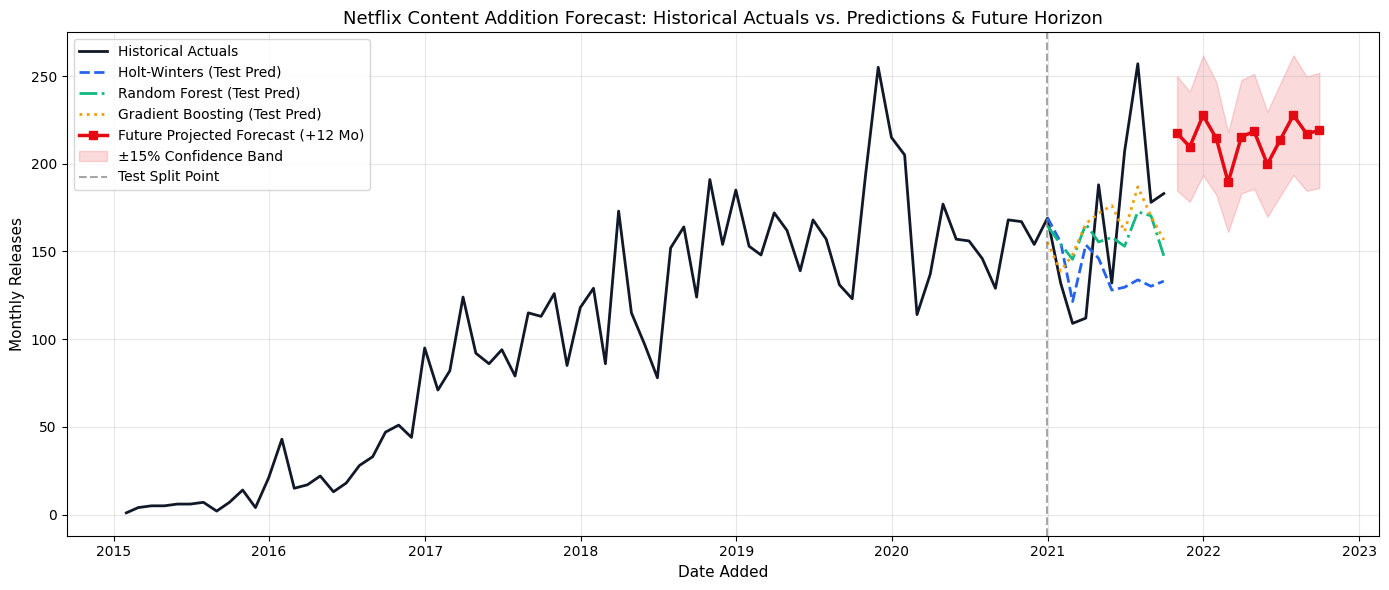

In [9]:
# Generate Out-Of-Sample Future Projections for next 12 Months using Holt-Winters and ML
full_hw = ExponentialSmoothing(
    ts_df['total_additions'],
    trend='add',
    seasonal='add',
    seasonal_periods=12
).fit()

FUTURE_HORIZON = 12
future_dates = pd.date_range(start=ts_df.index[-1] + pd.DateOffset(months=1), periods=FUTURE_HORIZON, freq='M')
future_hw_forecast = full_hw.forecast(steps=FUTURE_HORIZON)
future_hw_forecast.index = future_dates

# Plot Test Evaluation and Future Projections
plt.figure(figsize=(14, 6))
plt.plot(ts_df.index, ts_df['total_additions'], label='Historical Actuals', color='#111827', linewidth=2)

# Test Period Predictions
plt.plot(y_test.index, hw_preds, label='Holt-Winters (Test Pred)', color='#2563eb', linestyle='--', linewidth=2)
plt.plot(y_test.index, rf_preds, label='Random Forest (Test Pred)', color='#10b981', linestyle='-.', linewidth=2)
plt.plot(y_test.index, gb_preds, label='Gradient Boosting (Test Pred)', color='#f59e0b', linestyle=':', linewidth=2)

# Future Projection Line
plt.plot(future_dates, future_hw_forecast, label='Future Projected Forecast (+12 Mo)', color='#e50914', linewidth=2.5, marker='s')
plt.fill_between(future_dates, future_hw_forecast * 0.85, future_hw_forecast * 1.15, color='#e50914', alpha=0.15, label='±15% Confidence Band')

plt.axvline(x=y_test.index[0], color='gray', linestyle='--', alpha=0.7, label='Test Split Point')
plt.title('Netflix Content Addition Forecast: Historical Actuals vs. Predictions & Future Horizon', fontsize=13)
plt.xlabel('Date Added', fontsize=11)
plt.ylabel('Monthly Releases', fontsize=11)
plt.legend(loc='upper left', frameon=True)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## **Step 5: Evaluate Forecasting Accuracy & Extract Insights**

We evaluate forecasting performance using standard time-series error metrics:
1. **Mean Absolute Error (MAE):** Average magnitude of forecast errors in number of titles:
   $$\text{MAE} = \frac{1}{n} \sum_{t=1}^n |y_t - \hat{y}_t|$$
2. **Root Mean Squared Error (RMSE):** Penalizes larger forecast deviations more heavily:
   $$\text{RMSE} = \sqrt{\frac{1}{n} \sum_{t=1}^n (y_t - \hat{y}_t)^2}$$
3. **Mean Absolute Percentage Error (MAPE):** Relative percentage deviation:
   $$\text{MAPE} = \frac{100\%}{n} \sum_{t=1}^n \left|\frac{y_t - \hat{y}_t}{y_t}\right|$$
4. **$R^2$ Score:** Proportion of variance captured by the model.

TIME SERIES FORECASTING ACCURACY BENCHMARK


,Model,MAE (Titles),RMSE (Titles),MAPE (%),R² Score
0,Gradient Boosting Regressor,32.40,38.26,20.75,0.2438
1,Random Forest Regressor,35.69,42.20,22.04,0.0800
2,Holt-Winters Exponential Smoothing,42.19,54.91,23.12,-0.5575


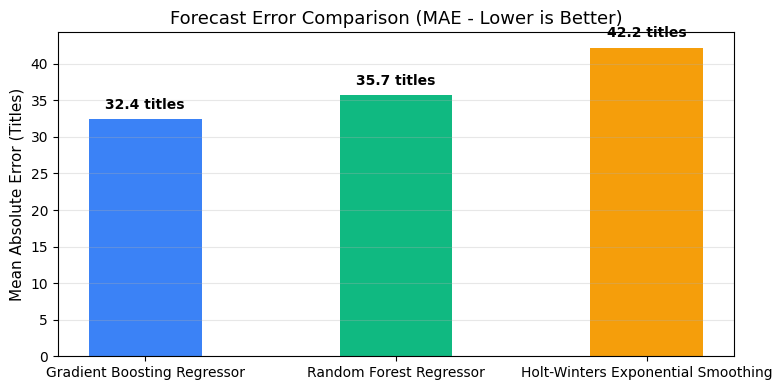

In [10]:
# Model Performance Evaluation on Test Set
def calculate_metrics(y_true, y_pred):
    mae = mean_absolute_error(y_true, y_pred)
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    mape = np.mean(np.abs((y_true - y_pred) / y_true)) * 100
    r2 = r2_score(y_true, y_pred)
    return mae, rmse, mape, r2

eval_models = {
    'Holt-Winters Exponential Smoothing': hw_preds,
    'Random Forest Regressor': rf_preds,
    'Gradient Boosting Regressor': gb_preds
}

comparison_list = []
for name, preds in eval_models.items():
    mae, rmse, mape, r2 = calculate_metrics(y_test, preds)
    comparison_list.append({
        'Model': name,
        'MAE (Titles)': round(mae, 2),
        'RMSE (Titles)': round(rmse, 2),
        'MAPE (%)': round(mape, 2),
        'R² Score': round(r2, 4)
    })

eval_df = pd.DataFrame(comparison_list).sort_values(by='MAE (Titles)').reset_index(drop=True)
print("=" * 75)
print("TIME SERIES FORECASTING ACCURACY BENCHMARK")
print("=" * 75)
display(eval_df)

# Visual comparison of Error Metrics
fig, ax = plt.subplots(figsize=(8, 4))
bars = ax.bar(eval_df['Model'], eval_df['MAE (Titles)'], color=['#3b82f6', '#10b981', '#f59e0b'], width=0.45)
ax.set_title('Forecast Error Comparison (MAE - Lower is Better)', fontsize=13)
ax.set_ylabel('Mean Absolute Error (Titles)', fontsize=11)
for bar in bars:
    yval = bar.get_height()
    ax.text(bar.get_x() + bar.get_width()/2.0, yval + 1, f"{yval:.1f} titles", ha='center', va='bottom', fontweight='bold')
ax.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

## **Interactive Trend & Forecast Explorer**

Select a projected time horizon below to view projected monthly addition volumes:

In [11]:
#@title Interactive Future Forecast Viewer
months_to_forecast = 6 #@param [3, 6, 9, 12] {type:"raw"}

projected_dates = pd.date_range(start=ts_df.index[-1] + pd.DateOffset(months=1), periods=months_to_forecast, freq='M')
projected_values = full_hw.forecast(steps=months_to_forecast)
projected_values.index = projected_dates

forecast_table = pd.DataFrame({
    'Month': [d.strftime('%B %Y') for d in projected_dates],
    'Projected Additions': projected_values.round().astype(int).values,
    'Lower Bound (-15%)': (projected_values * 0.85).round().astype(int).values,
    'Upper Bound (+15%)': (projected_values * 1.15).round().astype(int).values
})

print("=" * 65)
print(f"PROJECTED RELEASES FOR NEXT {months_to_forecast} MONTHS")
print("=" * 65)
display(forecast_table)
print(f"\nEstimated Total Expected Content Additions: {projected_values.sum():.0f} titles")

PROJECTED RELEASES FOR NEXT 6 MONTHS


,Month,Projected Additions,Lower Bound (-15%),Upper Bound (+15%)
0,October 2021,217,185,250
1,November 2021,210,178,241
2,December 2021,228,193,262
3,January 2022,215,182,247
4,February 2022,189,161,218
5,March 2022,215,183,248



Estimated Total Expected Content Additions: 1274 titles


In [12]:
# Install Gradio
!pip install -q gradio

In [ ]:
import gradio as gr
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np

def run_forecast_app(forecast_horizon, model_selection):
    # Re-train the selected model on the entire dataset to maximize projection quality
    # 1. Classical Holt-Winters
    full_hw = ExponentialSmoothing(
        ts_df['total_additions'],
        trend='add',
        seasonal='add',
        seasonal_periods=12
    ).fit()

    # Target future dates
    future_dates = pd.date_range(start=ts_df.index[-1] + pd.DateOffset(months=1), periods=forecast_horizon, freq='M')

    if model_selection == "Holt-Winters Exponential Smoothing":
        projected_values = full_hw.forecast(steps=forecast_horizon)
        projected_values.index = future_dates
    else:
        # ML recursive forecasting simulation
        last_known = ts_df['total_additions'].copy()
        ml_predictions = []

        # Select ML model
        ml_model = gb_reg if model_selection == "Gradient Boosting" else rf_reg

        for i in range(forecast_horizon):
            # Construct features on current history
            temp_feats = create_time_series_features(last_known)
            X_next = temp_feats.drop(columns=['y']).iloc[[-1]]
            pred_val = ml_model.predict(X_next)[0]
            ml_predictions.append(pred_val)

            # Append prediction to history to feed the next lag step recursively
            next_date = last_known.index[-1] + pd.DateOffset(months=1)
            last_known = pd.concat([last_known, pd.Series([pred_val], index=[next_date])])

        projected_values = pd.Series(ml_predictions, index=future_dates)

    # Generate Figure
    fig, ax = plt.subplots(figsize=(11, 5))
    ax.plot(ts_df.index, ts_df['total_additions'], label='Historical Actuals', color='#111827', linewidth=2)
    ax.plot(future_dates, projected_values, label=f'{model_selection} Projection', color='#e50914', linewidth=2.5, marker='o')
    ax.fill_between(future_dates, projected_values * 0.85, projected_values * 1.15, color='#e50914', alpha=0.15, label='±15% Band')
    ax.set_title(f'Netflix Content Demand Forecast Horizon ({model_selection})', fontsize=12)
    ax.set_xlabel('Date')
    ax.set_ylabel('Additions')
    ax.legend(loc='upper left')
    ax.grid(alpha=0.3)
    plt.tight_layout()

    # Forecast Summary Table
    forecast_table = pd.DataFrame({
        'Month': [d.strftime('%B %Y') for d in future_dates],
        'Projected': projected_values.round().astype(int).values,
        'Min Expected (-15%)': (projected_values * 0.85).round().astype(int).values,
        'Max Expected (+15%)': (projected_values * 1.15).round().astype(int).values
    })

    total_projected = int(round(projected_values.sum()))
    summary_text = f"### Estimated total content additions over next {forecast_horizon} months: {total_projected} titles"

    return fig, forecast_table, summary_text

# Interface design
interface = gr.Interface(
    fn=run_forecast_app,
    inputs=[
        gr.Slider(minimum=3, maximum=24, step=3, value=12, label="Forecast Horizon (Months)"),
        gr.Dropdown(
            choices=["Holt-Winters Exponential Smoothing", "Gradient Boosting", "Random Forest"],
            value="Holt-Winters Exponential Smoothing",
            label="Forecasting Engine"
        )
    ],
    outputs=[
        gr.Plot(label="Dynamic Projection Visualization"),
        gr.Dataframe(label="Detailed Output Matrix"),
        gr.Markdown()
    ],
    title="Netflix Trend Forecasting & Predictive Analytics Sandbox",
    description="Simulate Netflix release schedules and forecast future content catalog expansions using advanced statistical and machine learning architectures.",
    theme="default"
)

interface.launch(share=True, debug=True)

Colab notebook detected. This cell will run indefinitely so that you can see errors and logs. To turn off, set debug=False in launch().
* Running on public URL: https://bd546a93fcef745b07.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


Created dataset file at: .gradio/flagged/dataset1.csv
